In [1]:
import pandas as pd

In [ ]:
train_set = pd.read_csv("data/train_normal_rtf.csv")
test_set = pd.read_csv("data/test_normal_rtf.csv")

In [3]:
print("Train class distribution:")
print(train_set['label'].value_counts())
print(train_set['label'].value_counts(normalize=True).rename('proportion'))

print("\nTest class distribution:")
print(test_set['label'].value_counts())
print(test_set['label'].value_counts(normalize=True).rename('proportion'))

Train class distribution:
label
1    182
0    174
Name: count, dtype: int64
label
1    0.511236
0    0.488764
Name: proportion, dtype: float64

Test class distribution:
label
1    20
0    20
Name: count, dtype: int64
label
1    0.5
0    0.5
Name: proportion, dtype: float64


In [4]:
feature_cols = [str(i) for i in range(70)]

train_stats = train_set[feature_cols].agg(['mean', 'std']).T
test_stats  = test_set[feature_cols].agg(['mean', 'std']).T

comparison = train_stats.rename(columns={'mean': 'Train Mean', 'std': 'Train SD'})
comparison[['Test Mean', 'Test SD']] = test_stats[['mean', 'std']].values
print(comparison)

    Train Mean  Train SD  Test Mean   Test SD
0     0.519575  0.176560   0.541895  0.208996
1     0.424181  0.152259   0.444326  0.183981
2     0.404844  0.159494   0.446521  0.167564
3     0.496414  0.170667   0.513288  0.168811
4     0.384263  0.131792   0.427703  0.148368
..         ...       ...        ...       ...
65    0.465239  0.176755   0.465161  0.174536
66    0.465600  0.151644   0.480269  0.183109
67    0.485472  0.171723   0.516322  0.190701
68    0.564909  0.117335   0.571259  0.125676
69    0.254285  0.154218   0.264348  0.141942

[70 rows x 4 columns]


In [5]:
from scipy import stats

results = []
for col in feature_cols:
    stat, pval = stats.mannwhitneyu(train_set[col], test_set[col], alternative='two-sided')
    results.append({'Feature': col, 'MWU_stat': stat, 'p_value': pval})

results_df = pd.DataFrame(results)

# Apply Bonferroni correction for 70 features
alpha_corrected = 0.05 / 70
sig_count = (results_df['p_value'] < alpha_corrected).sum()
print(f"Features with significant difference (Bonferroni-corrected): {sig_count} / 70")

Features with significant difference (Bonferroni-corrected): 0 / 70


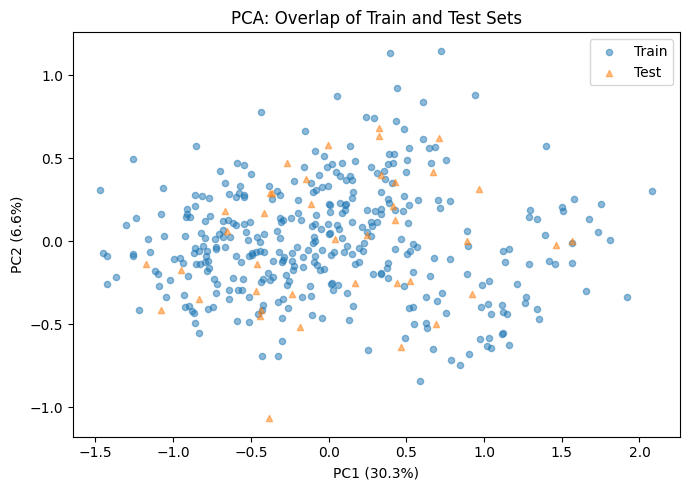

In [9]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

X_train = train_set[feature_cols].values
X_test  = test_set[feature_cols].values

pca = PCA(n_components=2)
pca.fit(X_train)

train_pca = pca.transform(X_train)
test_pca  = pca.transform(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(train_pca[:, 0], train_pca[:, 1], alpha=0.5, label='Train', s=20)
plt.scatter(test_pca[:, 0],  test_pca[:, 1],  alpha=0.5, label='Test',  s=20, marker='^')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('PCA: Overlap of Train and Test Sets')
plt.legend()
plt.tight_layout()
plt.savefig('pca_train_test_overlap.pdf')
plt.show()

In [7]:
for label_val, label_name in [(1, 'Positive'), (0, 'Negative')]:
    n_train = (train_set['label'] == label_val).sum()
    n_test  = (test_set['label']  == label_val).sum()
    total   = n_train + n_test
    print(f"{label_name}: Train={n_train} ({n_train/total:.1%}), Test={n_test} ({n_test/total:.1%})")

Positive: Train=182 (90.1%), Test=20 (9.9%)
Negative: Train=174 (89.7%), Test=20 (10.3%)
